# Market Comparison

The Goal of this notebook is to benchmark my pre-match prior function against real bookmaker odds, and do the same for live fair odds using the match-replay match as an example. This is a way of seeing how our live match odds compare to those of actual bookmakers and try to determine what the actual fair odds of a match would be

### Data/Imports

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

from src.prematch_prior import get_prematch_prior
from src.live_win_prob_model import get_live_win_prob, get_live_fair_odds

import joblib
import json

In [2]:
match_list = pd.read_parquet('../data/raw/statsbomb_match_list.parquet')
odds_data = pd.read_parquet('../data/raw/odds_data.parquet')

print(match_list.shape)
print(odds_data.shape)
odds_data.head()

(1140, 7)
(2283, 70)


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSCH,PSCD,PSCA,league_code,season_code
0,E0,16/08/14,Arsenal,Crystal Palace,2.0,1.0,H,1.0,1.0,D,...,-1.50,1.81,1.78,2.20,2.10,1.29,5.90,12.75,E0,1415
1,E0,16/08/14,Leicester,Everton,2.0,2.0,D,1.0,2.0,A,...,0.25,1.88,1.85,2.10,2.02,3.11,3.40,2.47,E0,1415
2,E0,16/08/14,Man United,Swansea,1.0,2.0,A,0.0,1.0,A,...,-1.50,2.18,2.08,1.87,1.79,1.45,4.81,8.25,E0,1415
3,E0,16/08/14,QPR,Hull,0.0,1.0,A,0.0,0.0,D,...,0.00,1.80,1.73,2.25,2.14,2.31,3.24,3.59,E0,1415
4,E0,16/08/14,Stoke,Aston Villa,0.0,1.0,A,0.0,0.0,D,...,-0.50,1.95,1.91,2.02,1.96,2.01,3.34,4.51,E0,1415


### Match the two datasets to eachother

In [3]:
# First check the names of the teams to see if there are any mismatches
statsbomb_names = set(match_list['home_team'].unique()) | set(match_list['away_team'].unique())
odds_names = set(odds_data['HomeTeam'].dropna().unique()) | set(odds_data['AwayTeam'].dropna().unique())

print(len(statsbomb_names), len(odds_names))

unmatched_statsbomb = statsbomb_names - odds_names
print(len(unmatched_statsbomb))
sorted(unmatched_statsbomb)

60 69
26


['AC Milan',
 'AFC Bournemouth',
 'AS Roma',
 'Athletic Club',
 'Atlético Madrid',
 'Celta Vigo',
 'Espanyol',
 'Hellas Verona',
 'Inter Milan',
 'Leicester City',
 'Levante UD',
 'Manchester City',
 'Manchester United',
 'Málaga',
 'Newcastle United',
 'Norwich City',
 'RC Deportivo La Coruña',
 'Rayo Vallecano',
 'Real Betis',
 'Real Sociedad',
 'Sporting Gijón',
 'Stoke City',
 'Swansea City',
 'Tottenham Hotspur',
 'West Bromwich Albion',
 'West Ham United']

In [4]:
for team in sorted(unmatched_statsbomb):
    candidates = [o for o in odds_names if any(word in o for word in team.split() if len(word) > 3)]
    print(f"{team!r} -> candidates: {candidates}")

'AC Milan' -> candidates: ['Milan']
'AFC Bournemouth' -> candidates: ['Bournemouth']
'AS Roma' -> candidates: ['Roma']
'Athletic Club' -> candidates: []
'Atlético Madrid' -> candidates: ['Ath Madrid', 'Real Madrid']
'Celta Vigo' -> candidates: ['Celta']
'Espanyol' -> candidates: []
'Hellas Verona' -> candidates: ['Verona']
'Inter Milan' -> candidates: ['Milan', 'Inter']
'Leicester City' -> candidates: ['Leicester', 'Man City']
'Levante UD' -> candidates: ['Levante']
'Manchester City' -> candidates: ['Man City']
'Manchester United' -> candidates: ['Man United']
'Málaga' -> candidates: []
'Newcastle United' -> candidates: ['Man United', 'Newcastle']
'Norwich City' -> candidates: ['Norwich', 'Man City']
'RC Deportivo La Coruña' -> candidates: []
'Rayo Vallecano' -> candidates: ['Vallecano']
'Real Betis' -> candidates: ['Real Madrid', 'Betis']
'Real Sociedad' -> candidates: ['Real Madrid', 'Sociedad']
'Sporting Gijón' -> candidates: []
'Stoke City' -> candidates: ['Man City', 'Stoke']
'Swa

In [5]:
# Check accent matching failures:
[o for o in odds_names if 'letic' in o.lower() or 'Ath' in o]  # Athletic Club
[o for o in odds_names if 'span' in o.lower()]                  # Espanyol
[o for o in odds_names if 'laga' in o.lower()]                  # Malaga
[o for o in odds_names if 'orun' in o.lower() or 'Depor' in o]  # Deportivo La Coruna
[o for o in odds_names if 'ijon' in o.lower() or 'Gijon' in o]  # Sporting Gijon

['Sp Gijon']

In [6]:
sorted(odds_names)

['Almeria',
 'Arsenal',
 'Aston Villa',
 'Atalanta',
 'Ath Bilbao',
 'Ath Madrid',
 'Barcelona',
 'Betis',
 'Bologna',
 'Bournemouth',
 'Burnley',
 'Cagliari',
 'Carpi',
 'Celta',
 'Cesena',
 'Chelsea',
 'Chievo',
 'Cordoba',
 'Crystal Palace',
 'Eibar',
 'Elche',
 'Empoli',
 'Espanol',
 'Everton',
 'Fiorentina',
 'Frosinone',
 'Genoa',
 'Getafe',
 'Granada',
 'Hull',
 'Inter',
 'Juventus',
 'La Coruna',
 'Las Palmas',
 'Lazio',
 'Leicester',
 'Levante',
 'Liverpool',
 'Malaga',
 'Man City',
 'Man United',
 'Milan',
 'Napoli',
 'Newcastle',
 'Norwich',
 'Palermo',
 'Parma',
 'QPR',
 'Real Madrid',
 'Roma',
 'Sampdoria',
 'Sassuolo',
 'Sevilla',
 'Sociedad',
 'Southampton',
 'Sp Gijon',
 'Stoke',
 'Sunderland',
 'Swansea',
 'Torino',
 'Tottenham',
 'Udinese',
 'Valencia',
 'Vallecano',
 'Verona',
 'Villarreal',
 'Watford',
 'West Brom',
 'West Ham']

In [7]:
# Full team mapping so names match up:
team_name_to_odds_name = {
    'AC Milan': 'Milan',
    'AFC Bournemouth': 'Bournemouth',
    'AS Roma': 'Roma',
    'Athletic Club': 'Ath Bilbao',
    'Atlético Madrid': 'Ath Madrid',
    'Celta Vigo': 'Celta',
    'Espanyol': 'Espanol',
    'Hellas Verona': 'Verona',
    'Inter Milan': 'Inter',
    'Leicester City': 'Leicester',
    'Levante UD': 'Levante',
    'Manchester City': 'Man City',
    'Manchester United': 'Man United',
    'Málaga': 'Malaga',
    'Newcastle United': 'Newcastle',
    'Norwich City': 'Norwich',
    'RC Deportivo La Coruña': 'La Coruna',
    'Rayo Vallecano': 'Vallecano',
    'Real Betis': 'Betis',
    'Real Sociedad': 'Sociedad',
    'Sporting Gijón': 'Sp Gijon',
    'Stoke City': 'Stoke',
    'Swansea City': 'Swansea',
    'Tottenham Hotspur': 'Tottenham',
    'West Bromwich Albion': 'West Brom',
    'West Ham United': 'West Ham',
}

In [8]:
match_list['home_team_odds_name'] = match_list['home_team'].replace(team_name_to_odds_name)
match_list['away_team_odds_name'] = match_list['away_team'].replace(team_name_to_odds_name)

check_home = set(match_list['home_team_odds_name'].unique()) - odds_names
check_away = set(match_list['away_team_odds_name'].unique()) - odds_names
print(check_home, check_away)

set() set()


In [9]:
# Check actual dtypes
print(match_list['match_date'].dtype)
print(odds_data['Date'].dtype)
print(match_list['match_date'].head(3))
print(odds_data['Date'].head(3))

object
object
0    2016-01-17
1    2015-09-23
2    2015-09-23
Name: match_date, dtype: object
0    16/08/14
1    16/08/14
2    16/08/14
Name: Date, dtype: object


In [10]:
# Convert odds date to datetime
odds_data['match_date'] = pd.to_datetime(odds_data['Date'], format='mixed', dayfirst=True)
print(odds_data['match_date'].dt.year.unique())

[2014. 2015.   nan 2016.]


In [11]:
# remove nan rows
bad_rows = odds_data[odds_data['match_date'].isna()]
print(len(bad_rows))
bad_rows[['Date', 'HomeTeam', 'AwayTeam']]

3


,Date,HomeTeam,AwayTeam
380,None,None,None
1901,None,None,None
2282,None,None,None


In [12]:
odds_data = odds_data.dropna(subset=['match_date'])
print(len(odds_data))

2280


In [13]:
# Convert match_listr to datetime as well
match_list['match_date'] = pd.to_datetime(match_list['match_date'])
match_list['match_date_only'] = match_list['match_date'].dt.normalize()

In [14]:
# Merge the lists
merged = match_list.merge(
    odds_data,
    left_on=['home_team_odds_name', 'away_team_odds_name', 'match_date'],
    right_on=['HomeTeam', 'AwayTeam', 'match_date'],
    how='inner'
)
print(len(merged))

1140


### Convert bookmaker odds to implied probability

In [15]:
odds_columns = [col for col in merged.columns if col.endswith('H') or col.endswith('D') or col.endswith('A')]
print(odds_columns)

['B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbAH', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSCH', 'PSCD', 'PSCA']


In [16]:
# Check Bet365 for NA values
merged['B365H'].isna().sum() 

np.int64(0)

In [17]:
# Convert to implied probability, removing the overround
merged['implied_prob_home_raw'] = 1 / merged['B365H']
merged['implied_prob_draw_raw'] = 1 / merged['B365D']
merged['implied_prob_away_raw'] = 1 / merged['B365A']

merged['overround'] = merged['implied_prob_home_raw'] + merged['implied_prob_draw_raw'] + merged['implied_prob_away_raw']
print(merged['overround'].describe())

count    1140.000000
mean        1.043380
std         0.013088
min         1.018069
25%         1.028508
50%         1.048477
75%         1.051693
max         1.070599
Name: overround, dtype: float64


In [18]:
merged['implied_prob_home'] = merged['implied_prob_home_raw'] / merged['overround']
merged['implied_prob_draw'] = merged['implied_prob_draw_raw'] / merged['overround']
merged['implied_prob_away'] = merged['implied_prob_away_raw'] / merged['overround']

check_sum = merged['implied_prob_home'] + merged['implied_prob_draw'] + merged['implied_prob_away']
print(check_sum.describe())

count    1.140000e+03
mean     1.000000e+00
std      9.080836e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


### Comparison of prematch tool vs the market

In [19]:
# Recompute priros directly
team_elo_history = pd.read_parquet('../data/processed/team_elo_history.parquet')
bin_edges = np.load('../data/processed/elo_bin_edges.npy')
draw_rate_by_bin = pd.read_pickle('../data/processed/draw_rate_by_bin.pkl')

def get_prior_for_row(row):
    prior = get_prematch_prior(
        row['home_team'], row['away_team'], row['match_date'],
        team_elo_history, bin_edges, draw_rate_by_bin
    )
    return pd.Series(prior)

prior_columns = merged.apply(get_prior_for_row, axis=1)
merged = pd.concat([merged, prior_columns], axis=1)
print(merged[['home_team', 'away_team', 'prob_home_win', 'prob_draw', 'prob_away_win']].head())

                home_team       away_team  prob_home_win  prob_draw  \
0             Real Madrid  Sporting Gijón       0.802006   0.173160   
1              Levante UD           Eibar       0.395742   0.328671   
2              Las Palmas         Sevilla       0.328702   0.262295   
3  RC Deportivo La Coruña          Getafe       0.522362   0.275072   
4                  Málaga      Levante UD       0.647607   0.227564   

   prob_away_win  
0       0.024834  
1       0.275586  
2       0.409003  
3       0.202567  
4       0.124829  


In [20]:
merged[merged['match_id'] == 3754291][['home_team', 'away_team', 'prob_home_win', 'prob_draw', 'prob_away_win']]

,home_team,away_team,prob_home_win,prob_draw,prob_away_win
520,Watford,Tottenham Hotspur,0.345368,0.328671,0.325961


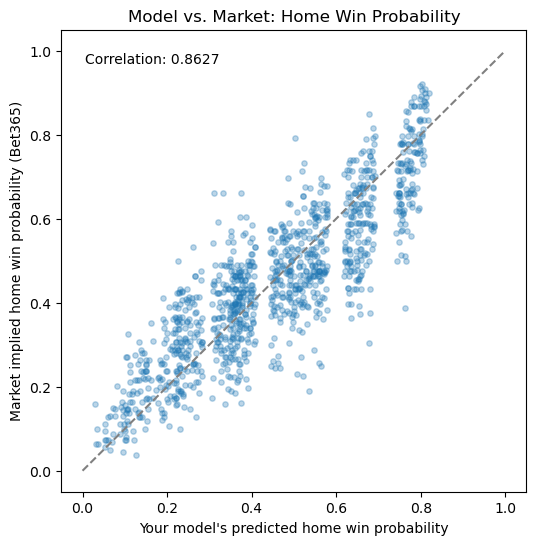

Correlation: 0.8627


In [21]:
# Calibration/ accuracy comparison
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(merged['prob_home_win'], merged['implied_prob_home'], alpha=0.3, s=15)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_xlabel('Your model\'s predicted home win probability')
ax.set_ylabel('Market implied home win probability (Bet365)')
ax.set_title('Model vs. Market: Home Win Probability')

correlation = merged['prob_home_win'].corr(merged['implied_prob_home'])
ax.text(0.05, 0.95, f'Correlation: {correlation:.4f}', transform=ax.transAxes, verticalalignment='top')

fig.savefig('../visuals/model_vs_market_scatter.png', dpi=150, bbox_inches='tight')

plt.show()
print(f"Correlation: {correlation:.4f}")

In [22]:
# Compare metrics directly against real outcomes
merged['result'] = np.where(
    merged['home_score'] > merged['away_score'], 'home_win',
    np.where(merged['home_score'] < merged['away_score'], 'away_win', 'draw')
)

y_true_onehot = pd.get_dummies(merged['result'])[['away_win', 'draw', 'home_win']].values

your_probs = merged[['prob_away_win', 'prob_draw', 'prob_home_win']].values
market_probs = merged[['implied_prob_away', 'implied_prob_draw', 'implied_prob_home']].values

your_brier = ((your_probs - y_true_onehot) ** 2).sum(axis=1).mean()
market_brier = ((market_probs - y_true_onehot) ** 2).sum(axis=1).mean()

your_logloss = log_loss(merged['result'], your_probs, labels=['away_win', 'draw', 'home_win'])
market_logloss = log_loss(merged['result'], market_probs, labels=['away_win', 'draw', 'home_win'])

print(f"Our model  - Brier: {your_brier:.4f}, Log loss: {your_logloss:.4f}")
print(f"Market odds - Brier: {market_brier:.4f}, Log loss: {market_logloss:.4f}")

Our model  - Brier: 0.6011, Log loss: 1.0080
Market odds - Brier: 0.5811, Log loss: 0.9746


In [23]:
match_list_sorted = merged.sort_values('match_date').reset_index(drop=True)
split_idx = int(len(match_list_sorted) * 0.8)
merged_test_only = match_list_sorted.iloc[split_idx:]

your_probs_test = merged_test_only[['prob_away_win', 'prob_draw', 'prob_home_win']].values
y_true_test = pd.get_dummies(merged_test_only['result'])[['away_win', 'draw', 'home_win']].values

your_brier_test = ((your_probs_test - y_true_test) ** 2).sum(axis=1).mean()
print(f"Your model, test-only subset - Brier: {your_brier_test:.4f}")

Your model, test-only subset - Brier: 0.5819


In [24]:
market_probs_test = merged_test_only[['implied_prob_away', 'implied_prob_draw', 'implied_prob_home']].values
market_brier_test = ((market_probs_test - y_true_test) ** 2).sum(axis=1).mean()
print(f"Market, test-only subset - Brier: {market_brier_test:.4f}")

Market, test-only subset - Brier: 0.5537


Model correlates well with market pricing (r=0.86) but trails on calibration (Brier 0.6011 vs 0.5811, log loss 1.0080 vs 0.9746) — a reasonable result for a single-feature Elo model against a market incorporating far more information. Both model and market improve similarly as the season progresses, suggesting no meaningful convergence, just shared benefit from more mature ratings.

### Live fair odds vs. a real sportsbook's in-play odds

In [25]:
import joblib
import json

xgb_model_v2 = joblib.load('../data/processed/xgb_live_model.pkl')
with open('../data/processed/live_model_feature_cols.json') as f:
    feature_cols = json.load(f)

snapshot_skeleton = pd.read_parquet('../data/processed/snapshot_features_full.parquet')

replay_data = snapshot_skeleton[snapshot_skeleton['match_id'] == 3754291].sort_values('snapshot_minute').reset_index(drop=True)
print(replay_data.shape)
replay_data[['snapshot_minute', 'score_diff', 'man_advantage']].head()

(96, 23)


,snapshot_minute,score_diff,man_advantage
0,0,0.0,0.0
1,1,0.0,0.0
2,2,0.0,0.0
3,3,0.0,0.0
4,4,0.0,0.0


In [26]:
# Run live fair odds function across the snapshots for the win probability chart
odds_predictions = []
for _, row in replay_data.iterrows():
    match_state = row[feature_cols].to_dict()
    odds = get_live_fair_odds(match_state, xgb_model_v2, feature_cols)
    odds_predictions.append(odds)

odds_df = pd.DataFrame(odds_predictions)
replay_data = pd.concat([replay_data.reset_index(drop=True), odds_df], axis=1)

replay_data[['snapshot_minute', 'odds_home', 'odds_draw', 'odds_away']].head(10)

,snapshot_minute,odds_home,odds_draw,odds_away
0,0,2.751737,3.118462,3.165335
1,1,2.760908,3.112560,3.159345
2,2,2.760908,3.112560,3.159345
3,3,2.760908,3.112560,3.159345
4,4,2.760908,3.112560,3.159345
5,5,2.760908,3.112560,3.159345
6,6,2.760908,3.112560,3.159345
7,7,2.760908,3.112560,3.159345
8,8,2.760908,3.112560,3.159345
9,9,2.760908,3.112560,3.159345


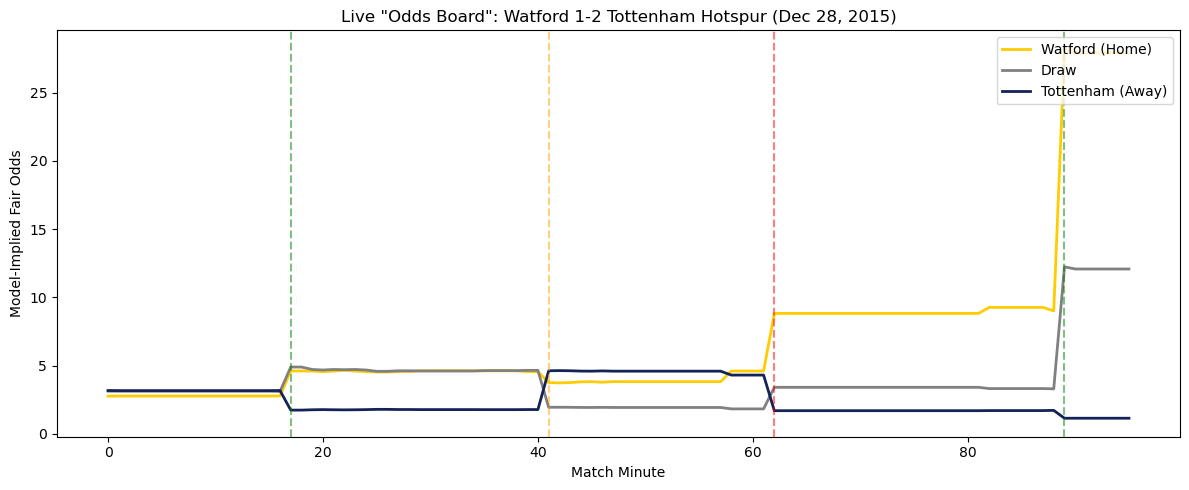

In [27]:
# Plot as a companion chart
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(replay_data['snapshot_minute'], replay_data['odds_home'], label='Watford (Home)', color='#FFCC00', linewidth=2)
ax.plot(replay_data['snapshot_minute'], replay_data['odds_draw'], label='Draw', color='gray', linewidth=2)
ax.plot(replay_data['snapshot_minute'], replay_data['odds_away'], label='Tottenham (Away)', color='#132257', linewidth=2)

ax.axvline(x=17, color='green', linestyle='--', alpha=0.5)
ax.axvline(x=41, color='orange', linestyle='--', alpha=0.5)
ax.axvline(x=62, color='red', linestyle='--', alpha=0.5)
ax.axvline(x=89, color='green', linestyle='--', alpha=0.5)

ax.set_xlabel('Match Minute')
ax.set_ylabel('Model-Implied Fair Odds')
ax.set_title('Live "Odds Board": Watford 1-2 Tottenham Hotspur (Dec 28, 2015)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()
fig.savefig('../visuals/live_odds_board.png', dpi=150, bbox_inches='tight')

Everything tracks correctly and inversely, exactly as it should: at minute 0, all three odds sit close together (~2.75-3.17, matching a near-even three-way prior). After Lamela's goal (17'), Tottenham's odds drop sharply to ~1.9 (heavily favored, low odds = short price), while Watford's climb to ~4.7. After Ighalo's equalizer (41'), it flips again toward a draw being likely (draw odds compress to ~1.9). After the red card (62'), Watford's odds balloon to ~9 (long shot), Tottenham's compress further. And after Son's winner (89'), Tottenham's odds collapse to ~1.15 (near-certain), while Watford's spike to ~24 and draw to ~12 — both reflecting "this is basically over.". Also worth noting this graph is dominated by the end of game spike for watford, this is mathematically correct and expected behavior for odds specifically.